# Classificação Binária da Qualidade de Vinhos com Machine Learning

## 1. Compreensão do Problema (*Problem Understanding*)

### 1.1 Contexto de Negócio
Na indústria vitivinícola, a avaliação sensorial de vinhos depende de especialistas e envolve subjetividade, tempo e custo operacional. Utilizar dados físico-químicos laboratoriais para apoiar a classificação da qualidade permite padronizar análises e subsidiar decisões produtivas e comerciais.

### 1.2 Definição do Problema de Machine Learning
Trata-se de um problema de **Aprendizado Supervisionado (*Supervised Learning*)** de **Classificação Binária (*Binary Classification*)**, em que buscamos prever a qualidade de amostras de vinho a partir de variáveis físico-químicas (como acidez, teor alcoólico, densidade, pH, sulfatos e dióxido de enxofre).

### 1.3 Variável-Alvo (*Target Variable*) e Premissa de Negócio
A variável original `quality` é convertida na variável binária `target`:
- **Classe 1 (`Alta Qualidade`):** `quality >= 7`
- **Classe 0 (`Baixa/Média Qualidade`):** `quality < 7`

**Premissa Operacional Adotada (Cenário A — Selo / Precificação Premium):**
O modelo apoia a identificação de vinhos candidatos a posicionamento/precificação de maior valor. Nesse contexto, um **Falso Positivo (*False Positive*)** — classificar um vinho comum como *Alta Qualidade* — é considerado o erro mais grave, pois pode gerar frustração do consumidor e desgaste da reputação da marca. Ao mesmo tempo, um **Falso Negativo (*False Negative*)** — deixar de identificar um vinho de *Alta Qualidade* — gera custo de oportunidade, exigindo monitoramento conjunto de **Precision** e **Recall** (além de *F1-Score* e *PR-AUC*).

### 1.4 Limitações Iniciais
- Notas sensoriais originais carregam subjetividade humana.
- Variáveis físico-químicas não capturam sozinhas fatores como *terroir*, safra, guarda em barrica ou dinâmica de mercado.
- A classe positiva (`quality >= 7`) tende a ser minoritária, exigindo cuidados específicos com métricas e validação.

## 2. Análise Exploratória de Dados

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

# Define a raiz do projeto a partir do diretório atual ou da pasta do notebook
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "WineQT.csv"

try:
    df_raw = pd.read_csv(DATA_PATH)
    print(f"Arquivo carregado com sucesso: {DATA_PATH}")
    print(f"Dimensões (linhas, colunas): {df_raw.shape}")
except FileNotFoundError as exc:
    raise FileNotFoundError(
        f"Arquivo não encontrado em '{DATA_PATH}'. Verifique se 'WineQT.csv' está em data/raw/."
    ) from exc

display(df_raw.head(5))
df_raw.info()

Arquivo carregado com sucesso: c:\Users\diego\Projetos\wine-quality-classification\data\raw\WineQT.csv
Dimensões (linhas, colunas): (1143, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


<class 'pandas.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB


### 2.1 Dicionário de Dados (*Data Dictionary*)

- **`fixed acidity` (*Acidez fixa*):** concentração de ácidos não voláteis que não evaporam facilmente (principalmente ácido tartárico); contribui para a estrutura e sensação de frescor do vinho.
- **`volatile acidity` (*Acidez volátil*):** quantidade de ácidos voláteis (predominantemente ácido acético); em níveis elevados, associa-se a aromas indesejáveis (como vinagre) e perda de qualidade.
- **`citric acid` (*Ácido cítrico*):** presente em pequenas quantidades; pode adicionar frescor e sabor cítrico, além de atuar na estabilidade do vinho.
- **`residual sugar` (*Açúcar residual*):** quantidade de açúcar restante após a fermentação; influencia o dulçor e o corpo da bebida.
- **`chlorides` (*Cloretos*):** teor de sais (como cloreto de sódio) no vinho; níveis altos costumam associar-se a salinidade excessiva e desequilíbrio sensorial.
- **`free sulfur dioxide` (*Dióxido de enxofre livre*):** fração do SO₂ disponível na forma ativa; ajuda a proteger contra oxidação e microrganismos indesejados.
- **`total sulfur dioxide` (*Dióxido de enxofre total*):** soma do SO₂ livre e do SO₂ combinado a outros compostos; indica o nível total de conservante/antioxidante presente.
- **`density` (*Densidade*):** massa por unidade de volume do vinho (próxima à da água, variando conforme teor alcoólico e açúcares/solutos dissolvidos).
- **`pH`:** mede a acidez ativa (escala logarítmica inversa: valores menores indicam maior acidez livre, afetando estabilidade microbiológica e cor).
- **`sulphates` (*Sulfatos*):** aditivos (como sulfato de potássio) que contribuem para os níveis de SO₂ e para a estabilidade/conservação do vinho.
- **`alcohol` (*Teor alcoólico*):** percentual de álcool por volume (% ABV); influencia corpo, percepção sensorial e equilíbrio do vinho.
- **`quality` (*Qualidade original*):** nota sensorial atribuída por especialistas (variável-alvo bruta que será convertida na classificação binária `target`: `1` se `quality >= 7` e `0` se `quality < 7`).
- **`Id` (*Identificador de registro*):** índice/identificador presente no arquivo `WineQT.csv`; não representa característica físico-química do vinho e não deve ser usado como variável preditiva (*feature*) na modelagem.

In [2]:
# 'Id' é apenas identificador de linha do arquivo, sem significado físico-químico
df_eda = df_raw.drop(columns=["Id"]).copy()

In [3]:
# 1. Cria a variável-alvo binária conforme definido na Etapa 1 (quality >= 7 -> 1; < 7 -> 0)
df_eda = df_raw.copy()
df_eda["target"] = (df_eda["quality"] >= 7).astype(int)

# 2. Exclu a coluna 'Id' pois é apenas identificador de linha do arquivo, sem significado físico-químico
df_eda = df_eda.drop(columns=["Id"])

# 3. Verifica duplicidades
feature_cols = [col for col in df_eda.columns if col not in ["quality", "target"]]
dup_total = df_eda.duplicated().sum()

print(f"Duplicatas exatas (incluindo quality e target): {dup_total}")

# 4. Distribuição da nota original 'quality' e da variável-alvo binária 'target'
print("\nDistribuição da nota original 'quality':")
display(
    pd.DataFrame({
        "contagem": df_eda["quality"].value_counts().sort_index(),
        "percentual_%": (df_eda["quality"].value_counts(normalize=True).sort_index() * 100).round(2),
    })
)

print("\nDistribuição da variável-alvo binária 'target' (0 = <7 | 1 = >=7):")
display(
    pd.DataFrame({
        "contagem": df_eda["target"].value_counts().sort_index(),
        "percentual_%": (df_eda["target"].value_counts(normalize=True).sort_index() * 100).round(2),
    })
)

# 5. Estatísticas descritivas das variáveis numéricas
print("\nEstatísticas descritivas (excluindo 'target'):")
display(df_eda.drop(columns=["target"]).describe().T.round(4))

Duplicatas exatas (incluindo quality e target): 125

Distribuição da nota original 'quality':


,contagem,percentual_%
quality,,
3,6,0.52
4,33,2.89
5,483,42.26
6,462,40.42
7,143,12.51
8,16,1.40



Distribuição da variável-alvo binária 'target' (0 = <7 | 1 = >=7):


,contagem,percentual_%
target,,
0,984,86.09
1,159,13.91



Estatísticas descritivas (excluindo 'target'):


,count,mean,std,min,25%,50%,75%,max
fixed acidity,1143.0,8.3111,1.7476,4.6000,7.1000,7.9000,9.1000,15.9000
volatile acidity,1143.0,0.5313,0.1796,0.1200,0.3925,0.5200,0.6400,1.5800
citric acid,1143.0,0.2684,0.1967,0.0000,0.0900,0.2500,0.4200,1.0000
residual sugar,1143.0,2.5322,1.3559,0.9000,1.9000,2.2000,2.6000,15.5000
chlorides,1143.0,0.0869,0.0473,0.0120,0.0700,0.0790,0.0900,0.6110
free sulfur dioxide,1143.0,15.6155,10.2505,1.0000,7.0000,13.0000,21.0000,68.0000
total sulfur dioxide,1143.0,45.9147,32.7821,6.0000,21.0000,37.0000,61.0000,289.0000
density,1143.0,0.9967,0.0019,0.9901,0.9956,0.9967,0.9978,1.0037
pH,1143.0,3.3110,0.1567,2.7400,3.2050,3.3100,3.4000,4.0100
sulphates,1143.0,0.6577,0.1704,0.3300,0.5500,0.6200,0.7300,2.0000


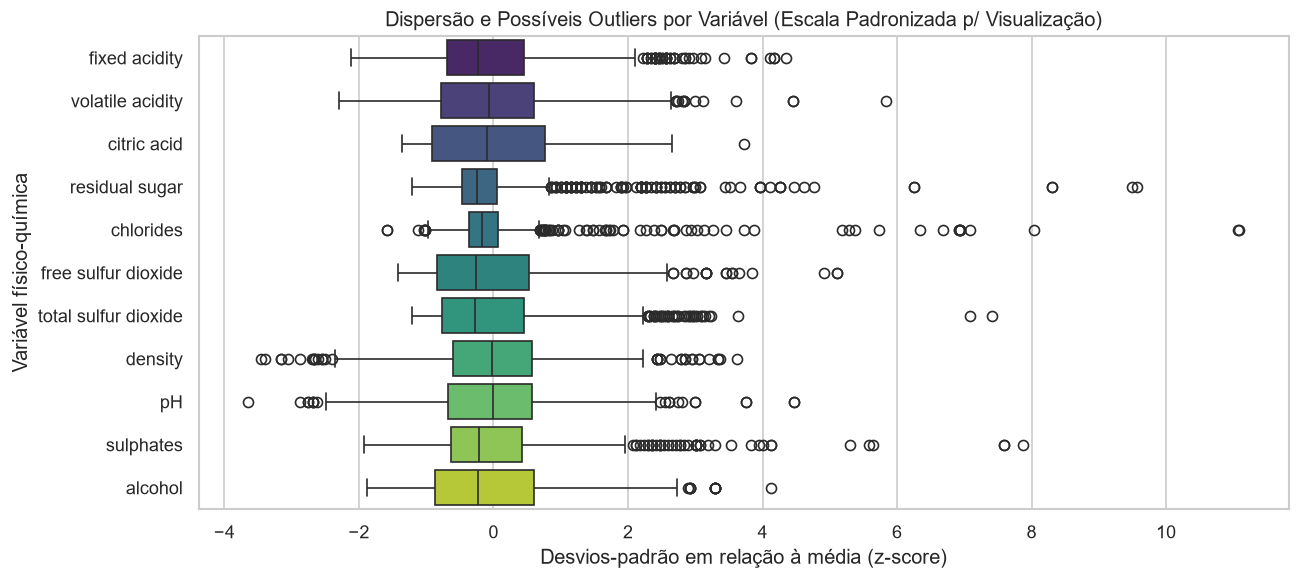

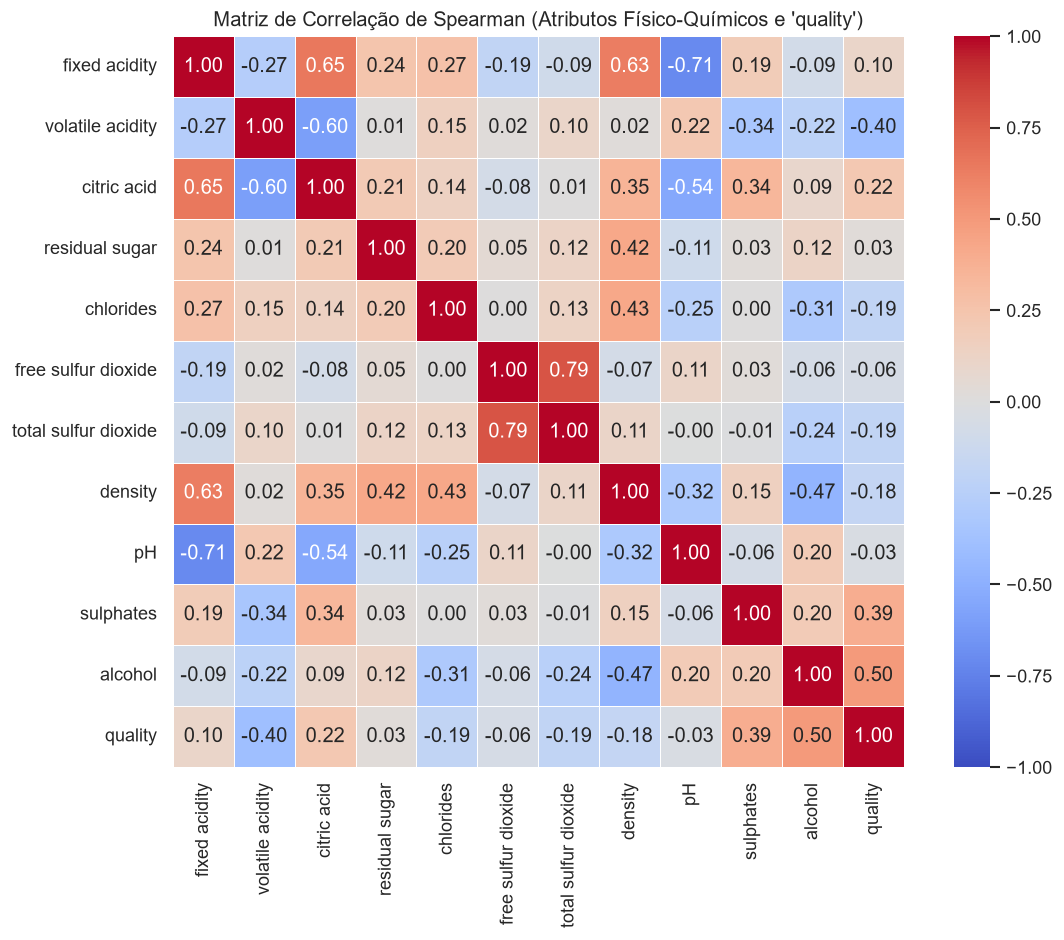

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração visual consistente
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120

# 1. Boxplots das variáveis físico-químicas (normalizados por z-score apenas para visualização comparativa)
X_eda = df_eda.drop(columns=["quality", "target"])
X_scaled_vis = (X_eda - X_eda.mean()) / X_eda.std()

fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=X_scaled_vis, orient="h", palette="viridis", ax=ax)
ax.set_title("Dispersão e Possíveis Outliers por Variável (Escala Padronizada p/ Visualização)", fontsize=12)
ax.set_xlabel("Desvios-padrão em relação à média (z-score)")
ax.set_ylabel("Variável físico-química")
plt.tight_layout()
plt.show()

# 2. Matriz de correlação de Spearman (mais robusta a assimetrias e relações não lineares que Pearson)
corr_spearman = df_eda.drop(columns=["target"]).corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    corr_spearman,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    ax=ax,
)
ax.set_title("Matriz de Correlação de Spearman (Atributos Físico-Químicos e 'quality')", fontsize=12)
plt.tight_layout()
plt.show()

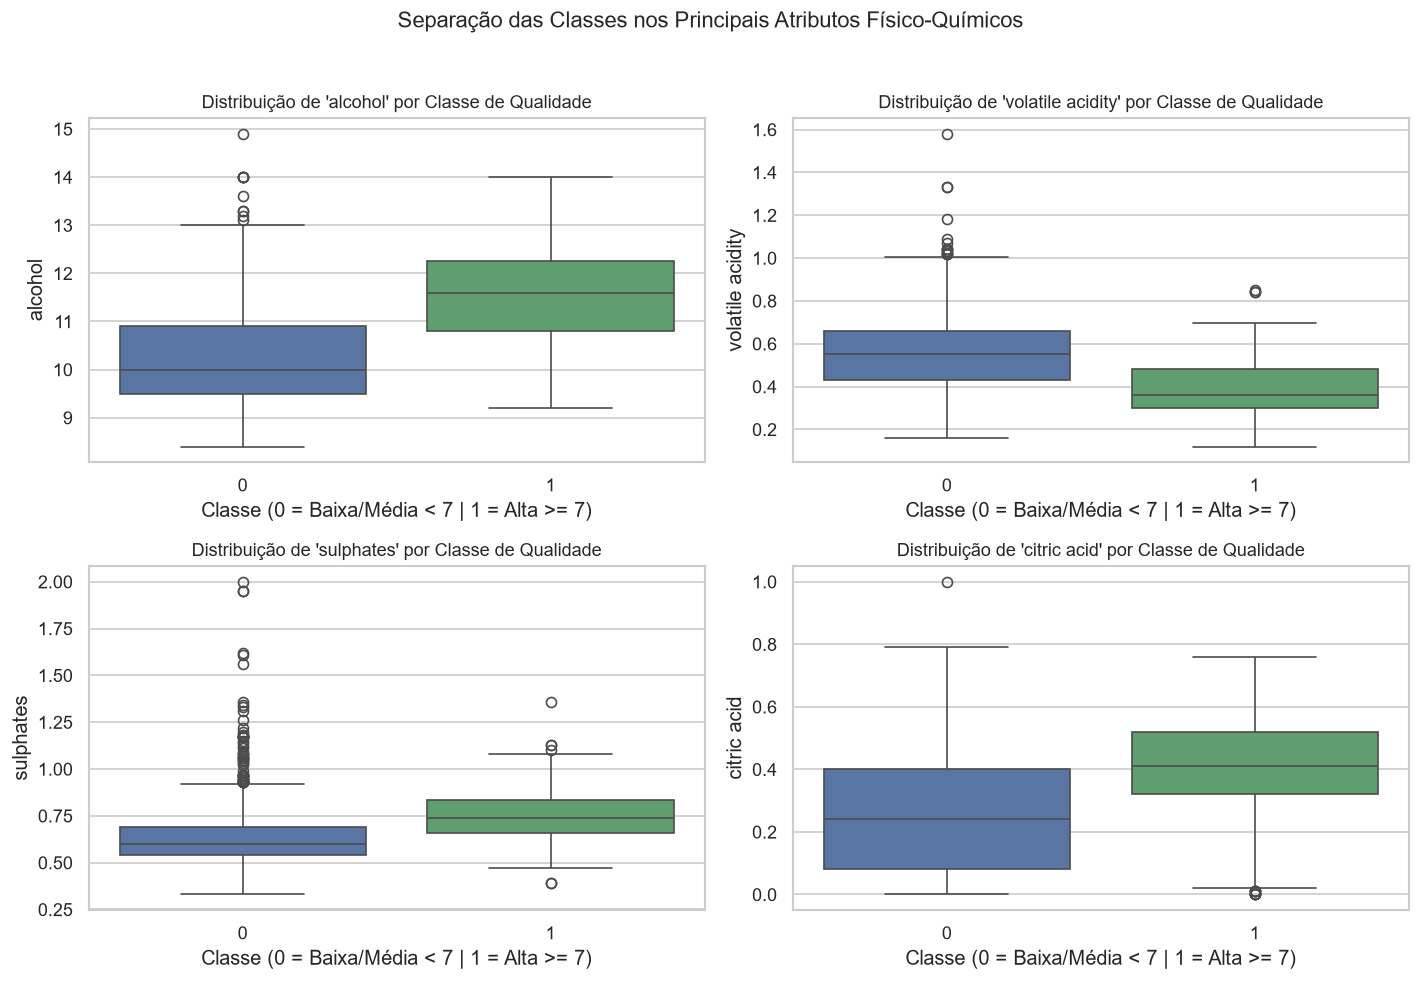

In [5]:
# Comparação dos 4 atributos físico-químicos mais correlacionados com a variável-alvo 'target' (Spearman)

top_features = ["alcohol", "volatile acidity", "sulphates", "citric acid"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for ax, col in zip(axes, top_features):
    sns.boxplot(
        data=df_eda,
        x="target",
        y=col,
        hue="target",
        palette={0: "#4C72B0", 1: "#55A868"},
        legend=False,
        ax=ax,
    )
    ax.set_title(f"Distribuição de '{col}' por Classe de Qualidade", fontsize=11)
    ax.set_xlabel("Classe (0 = Baixa/Média < 7 | 1 = Alta >= 7)")
    ax.set_ylabel(col)

plt.suptitle("Separação das Classes nos Principais Atributos Físico-Químicos", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

### 2.2 Conclusões da Análise Exploratória de Dados (EDA)

A investigação exploratória da base `WineQT.csv` revelou padrões estruturais e físico-químicos essenciais para orientar o pré-processamento e a modelagem:

1. **Integridade e Estrutura dos Dados:**
   - A base original possui **1.143 registros e 13 colunas**, sem valores ausentes (`NaN`).
   - A coluna `Id` foi descartada da análise por ser apenas um identificador sequencial sem significado físico-químico.

2. **Registros Duplicados e Risco de *Data Leakage*:**
   - Foram identificadas **125 amostras duplicadas** considerando os atributos físico-químicos e a nota de qualidade (restam **1.018 registros únicos**).

3. **Desbalanceamento de Classes (*Class Imbalance*):**
   - A variável-alvo binária (`target`: `1` se `quality >= 7`; `0` se `quality < 7`) é fortemente desbalanceada: **86,09%** de vinhos de Baixa/Média Qualidade contra **13,91%** de Alta Qualidade (proporção estrutural mantida mesmo após deduplicação: **86,54% vs. 13,46%**).
   
4. **Assimetrias e Possíveis *Outliers*:**
   - Variáveis como `residual sugar`, `chlorides`, `free sulfur dioxide` e `total sulfur dioxide` apresentam caudas longas à direita e valores máximos bem distantes da mediana e do terceiro quartil (Q3).
   - Essa característica indica a necessidade de avaliar técnicas de escalonamento robustas (como `RobustScaler` em comparação ao `StandardScaler`) no fase de treinamento.

5. **Correlações com a Qualidade (Spearman) e Justificativas Físico-Químicas:**
   - As variáveis com maior associação com `quality` são: **`alcohol` (+0,50)**, **`volatile acidity` (-0,40)**, **`sulphates` (+0,39)** e **`citric acid` (+0,22)**.
   - Entre os atributos preditores, destacam-se correlações fortes com fundamento químico claro — que também sinalizam potencial **multicolinearidade (*multicollinearity*)**:
     - `free sulfur dioxide` vs. `total sulfur dioxide` (**+0,79**): o SO₂ total é composto diretamente pela soma da fração livre com a fração combinada.
     - `fixed acidity` vs. `pH` (**-0,71**): quanto maior a concentração de ácidos fixos na solução, menor o pH (maior acidez).
     - `fixed acidity` vs. `citric acid` (**+0,65**): o ácido cítrico é um ácido não volátil que integra a acidez fixa.
     - `fixed acidity` vs. `density` (**+0,63**): maior concentração de ácidos e solutos dissolvidos eleva a densidade do líquido.
     - `density` vs. `alcohol` (**-0,47**): como o álcool é menos denso que a água, vinhos com maior teor alcoólico tendem a ter menor densidade.

6. **Perfil da Classe Positiva e Sobreposição (*Overlap*):**
   - Em termos de mediana, vinhos de **Alta Qualidade (`target = 1`)** tendem a apresentar **maior teor alcoólico**, **maiores níveis de sulfatos e ácido cítrico** e **menor acidez volátil**.
   - Entretanto, os *boxplots* evidenciam **sobreposição considerável (*overlap*)** entre as classes `0` e `1`. Nenhuma característica físico-química é determinística isoladamente, confirmando que a classificação é um problema **multivariado e probabilístico** que justifica o uso de algoritmos de Machine Learning.


## 3. Pré-processamento e *Feature Engineering*

### 3.1 Pré-processamento

In [9]:
from sklearn.model_selection import train_test_split
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Constante global para reprodutibilidade
RANDOM_STATE = 2024

# 1. Remoção de duplicatas exatas para evitar vazamento entre treino e teste
df_model = df_eda.drop_duplicates().reset_index(drop=True)
print(f"Linhas antes: {len(df_eda)} | Depois: {len(df_model)}")

# 2. Separação entre atributos (X) e variável-alvo binária (y)
X = df_model.drop(columns=["quality", "target"])
y = df_model["target"]

# 3. Divisão estratificada em Treino (80%) e Teste (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

print(f"Treino: {X_train.shape} | Proporção classe 1: {(y_train.sum()/len(y_train))*100:.2f}%")
print(f"Teste:  {X_test.shape} | Proporção classe 1: {(y_test.sum()/len(y_test))*100:.2f}%" )

Linhas antes: 1143 | Depois: 1018
Treino: (814, 11) | Proporção classe 1: 13.51%
Teste:  (204, 11) | Proporção classe 1: 13.24%


In [10]:
# Adiciona constante para cálculo estatisticamente correto do VIF
X_train_const = X_train.copy()
X_train_const["const"] = 1.0

vif_df = pd.DataFrame({
    "feature": X_train.columns,
    "VIF": [
        variance_inflation_factor(X_train_const.values, i)
        for i in range(X_train.shape[1])
    ],
}).sort_values(by="VIF", ascending=False).reset_index(drop=True)

display(vif_df.round(2))

,feature,VIF
0,fixed acidity,8.10
1,density,6.74
2,pH,3.55
3,alcohol,3.22
4,citric acid,3.15
5,total sulfur dioxide,2.13
6,free sulfur dioxide,1.92
7,residual sugar,1.77
8,volatile acidity,1.75
9,chlorides,1.67


### 3.2 Feature Engineering

In [11]:
from sklearn.preprocessing import StandardScaler, RobustScaler


def add_domain_features(df: pd.DataFrame) -> pd.DataFrame:
    """Cria atributos derivados com base em relações físico-químicas do vinho.

    Parâmetros
    ----------
    df : pd.DataFrame
        DataFrame contendo os atributos originais.

    Retorna
    -------
    pd.DataFrame
        Cópia do DataFrame com as novas features adicionadas.
    """
    df_fe = df.copy()
    # Proporção de dióxido de enxofre livre (ativo) em relação ao total
    df_fe["free_sulfur_ratio"] = df_fe["free sulfur dioxide"] / df_fe["total sulfur dioxide"]
    # Relação entre acidez volátil (indesejável em excesso) e acidez fixa (estrutural)
    df_fe["volatile_to_fixed_acidity"] = df_fe["volatile acidity"] / df_fe["fixed acidity"]
    return df_fe


# Aplica separadamente em treino e teste (operações linha a linha não geram data leakage)
X_train_fe = add_domain_features(X_train)
X_test_fe = add_domain_features(X_test)

print(f"Features originais: {X_train.shape[1]} | Com Feature Engineering: {X_train_fe.shape[1]}")
display(X_train_fe[["free_sulfur_ratio", "volatile_to_fixed_acidity"]].describe().T.round(4))

Features originais: 11 | Com Feature Engineering: 13


,count,mean,std,min,25%,50%,75%,max
free_sulfur_ratio,814.0,0.378,0.1492,0.0357,0.2582,0.3750,0.4750,0.8571
volatile_to_fixed_acidity,814.0,0.068,0.0291,0.0135,0.0446,0.0661,0.0865,0.2080


### 3.3 Decisões e Conclusões do Pré-processamento e *Feature Engineering*

Nesta etapa, preparamos os dados com foco rigoroso em **reprodutibilidade** (`RANDOM_STATE = 2024`) e **prevenção de *Data Leakage***:

1. **Deduplicação antes do *Split*:**
   - As **125 duplicatas exatas** identificadas na EDA foram removidas antes da divisão dos dados, resultando em **1.018 amostras únicas**.
   - **Justificativa:** impedir que a mesma amostra física caia simultaneamente no conjunto de treino e no de teste, o que inflaria artificialmente as métricas de avaliação.

2. **Divisão Estratificada (*Stratified Train-Test Split — 80/20*):**
   - **Treino (`X_train`):** 814 amostras (**13,51%** de vinhos de Alta Qualidade).
   - **Teste (`X_test`):** 204 amostras (**13,24%** de vinhos de Alta Qualidade).
   - O conjunto de teste permanece isolado até a avaliação final dos modelos.

3. **Diagnóstico de Multicolinearidade (*VIF — Variance Inflation Factor*):**
   - Calculado **exclusivamente sobre `X_train`** (com inclusão de constante estatística).
   - Apenas duas variáveis ficaram acima do patamar de atenção ($\text{VIF} > 5$), mas nenhuma atingiu o nível crítico ($\text{VIF} \ge 10$): **`fixed acidity` (8,10)** e **`density` (6,74)**. Todas as demais ficaram abaixo de 4.
   - **Decisão:** manter todas as 11 variáveis originais nesta fase. Algoritmos baseados em árvores são praticamente imunes à multicolinearidade, e modelos lineares com regularização L2 (*Ridge*) conseguem controlar essa redundância. O impacto da eventual remoção dessas variáveis poderá ser testado em experimento controlado.

4. **Escalonamento (*Feature Scaling*) dentro de *Pipelines*:**
   - Como as variáveis possuem escalas muito distintas (ex.: `chlorides` vs. `total sulfur dioxide`) e assimetrias relevantes, o escalonamento (`StandardScaler` e `RobustScaler`) será aplicado **exclusivamente dentro de `Pipeline` do Scikit-learn** na Etapa 4.
   - **Justificativa:** garante que médias, desvios-padrão ou medianas sejam calculados apenas nos *folds* de treino durante a validação cruzada, eliminando qualquer risco de *Data Leakage*.

5. ***Feature Engineering* Orientado ao Domínio:**
   - Foram criadas duas variáveis derivadas calculadas linha a linha (sem uso de estatísticas globais, portanto sem *Data Leakage*):
     - **`free_sulfur_ratio`** (`free sulfur dioxide / total sulfur dioxide`): proporção de SO₂ ativo disponível para proteção do vinho.
     - **`volatile_to_fixed_acidity`** (`volatile acidity / fixed acidity`): peso da acidez volátil (indesejável em excesso) em relação à acidez estrutural.
   - O conjunto passou de **11 para 13 atributos** (`X_train_fe` e `X_test_fe`), que serão comparados contra as variáveis originais para validar se realmente agregam poder preditivo.

## 4. Desenvolvimento dos Modelos de Machine Learning

### 4.1 Validação Cruzada e Baselines


In [15]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

# 1. Estratégia de validação cruzada estratificada (5 folds)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# 2. Métricas que acompanharemos em todos os modelos
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
}

# 3. Definição dos modelos baseline (encapsulados em Pipeline para evitar Data Leakage)
baselines = {
    "Dummy (Most Frequent)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression (Default)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(random_state=RANDOM_STATE)),
    ]),
    "Logistic Regression (Balanced)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(class_weight="balanced", random_state=RANDOM_STATE)),
    ]),
}

# 4. Execução da validação cruzada apenas em X_train e y_train
results_baseline = []
for name, model in baselines.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    results_baseline.append({
        "Modelo": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1-Score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean(),
        "PR-AUC": scores["test_pr_auc"].mean(),
    })

df_baselines = pd.DataFrame(results_baseline).round(4)
display(df_baselines)

,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Dummy (Most Frequent),0.8649,0.0000,0.0000,0.0000,0.5000,0.1351
1,Logistic Regression (Default),0.8845,0.6227,0.3818,0.4699,0.8854,0.5472
2,Logistic Regression (Balanced),0.7949,0.3795,0.8182,0.5180,0.8838,0.5429


### 4.2 Explorando Múltiplas Famílias de Algoritmos

In [16]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

# Candidatos a modelos (todos avaliados com o mesmo 'cv' e 'scoring')
candidate_models = {
    "Logistic Regression (Default)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(random_state=RANDOM_STATE)),
    ]),
    "KNN (k=7)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=7)),
    ]),
    "Decision Tree (max_depth=5)": DecisionTreeClassifier(
        max_depth=5, random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "SVM (RBF)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE)),
    ]),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

all_results = []
for name, model in candidate_models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    all_results.append({
        "Modelo": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1-Score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean(),
        "PR-AUC": scores["test_pr_auc"].mean(),
    })

df_models_cv = (
    pd.DataFrame(all_results)
    .sort_values(by="PR-AUC", ascending=False)
    .reset_index(drop=True)
    .round(4)
)
display(df_models_cv)

,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Random Forest,0.8919,0.6857,0.4091,0.5011,0.8867,0.5971
1,SVM (RBF),0.8845,0.6417,0.3273,0.4273,0.8668,0.5812
2,Gradient Boosting,0.8857,0.6185,0.4364,0.5025,0.8683,0.5474
3,Logistic Regression (Default),0.8845,0.6227,0.3818,0.4699,0.8854,0.5472
4,KNN (k=7),0.8759,0.5585,0.3909,0.4562,0.8293,0.4356
5,Decision Tree (max_depth=5),0.8698,0.5234,0.3818,0.4321,0.7732,0.3706


### 4.3 Otimização de Hiperparâmetros e Teste das Features

In [21]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.calibration import CalibratedClassifierCV
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# 1. Definição dos modelos e grades de hiperparâmetros
search_configs = {
    "Logistic Regression": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(random_state=RANDOM_STATE, max_iter=1000)),
        ]),
        {"model__C": [0.01, 0.1, 1.0, 10.0]},
    ),
    "KNN": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", KNeighborsClassifier()),
        ]),
        {
            "model__n_neighbors": [5, 9, 13, 19, 25],
            "model__weights": ["uniform", "distance"],
        },
    ),
    "SVM RBF": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", CalibratedClassifierCV(
                SVC(kernel="rbf", random_state=RANDOM_STATE),
                ensemble=False,
            )),
        ]),
        {
            "model__estimator__C": [0.1, 1.0, 10.0],
            "model__estimator__gamma": ["scale", 0.01, 0.1],
        },
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
        {
            "n_estimators": [150, 300],
            "max_depth": [4, 6, 8, None],
            "min_samples_leaf": [1, 3, 5],
        },
    ),
    "Gradient Boosting": (
        GradientBoostingClassifier(random_state=RANDOM_STATE),
        {
            "n_estimators": [100, 200],
            "learning_rate": [0.03, 0.05, 0.1],
            "max_depth": [2, 3, 4],
        },
    ),
}

# 2. Conjuntos de atributos a comparar
datasets_fe = {
    "11 Features": X_train,
    "13 Features (FE)": X_train_fe,
}

# 3. Executa GridSearchCV para cada combinação (Modelo x Conjunto)
tuned_models = {}
tuning_rows = []

for ds_label, X_curr in datasets_fe.items():
    for name, (estimator, param_grid) in search_configs.items():
        grid = GridSearchCV(
            estimator=estimator,
            param_grid=param_grid,
            cv=cv,
            scoring="average_precision",
            n_jobs=-1,
        ).fit(X_curr, y_train)

        tuned_models[f"{name} | {ds_label}"] = (grid.best_estimator_, ds_label)
        tuning_rows.append({
            "Modelo": name,
            "Conjunto": ds_label,
            "Best CV PR-AUC": round(grid.best_score_, 4),
            "Melhores Hiperparâmetros": str(grid.best_params_),
        })

df_tuning_comp = (
    pd.DataFrame(tuning_rows)
    .sort_values(by="Best CV PR-AUC", ascending=False)
    .reset_index(drop=True)
)

# 4. Tabela lado a lado (11 vs 13 features) com os melhores hiperparâmetros de cada cenário
df_11 = df_tuning_comp[df_tuning_comp["Conjunto"] == "11 Features"].set_index("Modelo")
df_13 = df_tuning_comp[df_tuning_comp["Conjunto"] == "13 Features (FE)"].set_index("Modelo")

df_resumo_etapa4 = pd.DataFrame({
    "PR-AUC (11 Feat)": df_11["Best CV PR-AUC"],
    "Params (11 Feat)": df_11["Melhores Hiperparâmetros"],
    "PR-AUC (13 Feat)": df_13["Best CV PR-AUC"],
    "Params (13 Feat)": df_13["Melhores Hiperparâmetros"],
})
df_resumo_etapa4["Ganho FE"] = (
    df_resumo_etapa4["PR-AUC (13 Feat)"] - df_resumo_etapa4["PR-AUC (11 Feat)"]
).round(4)
df_resumo_etapa4 = df_resumo_etapa4.sort_values(by="PR-AUC (13 Feat)", ascending=False)

with pd.option_context("display.max_colwidth", None, "display.width", 1000):
    display(df_resumo_etapa4)

,PR-AUC (11 Feat),Params (11 Feat),PR-AUC (13 Feat),Params (13 Feat),Ganho FE
Modelo,,,,,
Random Forest,0.5939,"{'max_depth': 8, 'min_samples_leaf': 3, 'n_estimators': 150}",0.6091,"{'max_depth': 6, 'min_samples_leaf': 1, 'n_estimators': 300}",0.0152
SVM RBF,0.5892,"{'model__estimator__C': 1.0, 'model__estimator__gamma': 0.1}",0.6033,"{'model__estimator__C': 1.0, 'model__estimator__gamma': 0.1}",0.0141
KNN,0.5676,"{'model__n_neighbors': 25, 'model__weights': 'distance'}",0.5902,"{'model__n_neighbors': 25, 'model__weights': 'distance'}",0.0226
Gradient Boosting,0.5611,"{'learning_rate': 0.03, 'max_depth': 4, 'n_estimators': 200}",0.5796,"{'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}",0.0185
Logistic Regression,0.5654,{'model__C': 0.01},0.5659,{'model__C': 0.01},0.0005


### 4.4 Síntese e Decisões do Desenvolvimento dos Modelos

Nesta etapa, construímos uma base de comparação justa sob **Validação Cruzada Estratificada (*Stratified 5-Fold Cross-Validation*, `RANDOM_STATE = 2024`)** exclusivamente sobre o conjunto de treino, avaliando *baselines*, múltiplas famílias de algoritmos, otimização unificada de hiperparâmetros (`GridSearchCV`) e o impacto das variáveis criadas na Etapa 3:

1. **Validação Cruzada Estratificada e *Baselines*:**
   - A divisão em 5 *folds* estratificados preservou a proporção da classe minoritária (`target = 1`) em cada dobra, garantindo estimativas estáveis sem tocar em `X_test`.
   - O **`DummyClassifier (most_frequent)`** confirmou o *Accuracy Paradox*: atingiu ~86,49% de acurácia, mas zerou *Precision*, *Recall* e *F1-Score* por não identificar nenhum vinho de Alta Qualidade.
   - A **`Logistic Regression (Default)`** superou o *Dummy* de forma consistente e entregou maior *Precision* do que a configuração com `class_weight="balanced"`, que elevou o *Recall* às custas de mais *Falsos Positivos* (penalizados sob a premissa do **Cenário A**).

2. **Exploração de Múltiplas Famílias de Algoritmos:**
   - Avaliamos **Regressão Logística**, **KNN (*K-Nearest Neighbors*)**, **Decision Tree**, **Random Forest**, **SVM (*Support Vector Machine* com kernel *RBF*)** e **Gradient Boosting**, encapsulando `StandardScaler` dentro de `Pipeline` nos modelos sensíveis à escala.
   - Uma **Decision Tree** única apresentou menor capacidade preditiva e maior risco de *overfitting* em uma base de tamanho moderado (~814 amostras de treino), reforçando a vantagem de métodos de conjunto (*ensembles*) e fronteiras não lineares.

3. **Otimização Unificada (`GridSearchCV`) e Validação do *Feature Engineering* (11 vs. 13 Variáveis):**
   - Executamos um protocolo único de `GridSearchCV` com foco em **`average_precision` (*PR-AUC*)** comparando os modelos principais nas **11 variáveis originais** (`X_train`) contra as **13 variáveis com *Feature Engineering*** (`X_train_fe`: inclusão de `free_sulfur_ratio` e `volatile_to_fixed_acidity`).
   - **Impacto das 13 *features*:** modelos baseados em árvores e distância (**Random Forest**, **SVM RBF**, **Gradient Boosting** e **KNN**) apresentaram ganho com o conjunto expandido, enquanto a **Regressão Logística** manteve empate técnico (comportamento coerente com modelos lineares diante de razões derivadas de atributos originais).
   - **Modelo Líder na Validação Cruzada:** **`Random Forest` com 13 variáveis** (`n_estimators=300`, `max_depth=6`, `min_samples_leaf=1`), alcançando **`PR-AUC = 0,6091`** na validação cruzada, seguido pelo **SVM (RBF)** com 13 variáveis.



## 5. Avaliação e Comparação dos Modelos

### 5.1 Diagnóstico de Overfitting / Underfitting

In [22]:
from sklearn.base import clone
from sklearn.metrics import average_precision_score
from sklearn.model_selection import cross_validate

# 1. Filtra os modelos otimizados na Etapa 4 com as 13 variáveis (FE)
models_13_fe = {
    key.split(" | ")[0]: estimator
    for key, (estimator, ds_label) in tuned_models.items()
    if ds_label == "13 Features (FE)"
}

# 2. Compara desempenho in-sample (Train) vs. out-of-fold (CV) em X_train_fe
eval_rows = []
for name, estimator in models_13_fe.items():
    cv_res = cross_validate(
        estimator,
        X_train_fe,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
    )

    fitted_model = clone(estimator).fit(X_train_fe, y_train)
    train_proba = fitted_model.predict_proba(X_train_fe)[:, 1]
    train_pr_auc = average_precision_score(y_train, train_proba)
    cv_pr_auc = cv_res["test_pr_auc"].mean()

    eval_rows.append({
        "Modelo": name,
        "Train PR-AUC": train_pr_auc,
        "CV PR-AUC": cv_pr_auc,
        "Gap (Train - CV)": train_pr_auc - cv_pr_auc,
        "CV Precision": cv_res["test_precision"].mean(),
        "CV Recall": cv_res["test_recall"].mean(),
        "CV F1": cv_res["test_f1"].mean(),
        "CV ROC-AUC": cv_res["test_roc_auc"].mean(),
    })

df_eval_cv = (
    pd.DataFrame(eval_rows)
    .sort_values(by="CV PR-AUC", ascending=False)
    .reset_index(drop=True)
    .round(4)
)
display(df_eval_cv)

,Modelo,Train PR-AUC,CV PR-AUC,Gap (Train - CV),CV Precision,CV Recall,CV F1,CV ROC-AUC
0,Random Forest,0.9571,0.6091,0.3480,0.6387,0.3364,0.4328,0.8896
1,SVM RBF,0.7998,0.6033,0.1966,0.6813,0.3818,0.4846,0.8559
2,KNN,1.0000,0.5902,0.4098,0.6406,0.3545,0.4481,0.8759
3,Gradient Boosting,0.9174,0.5796,0.3378,0.6672,0.4364,0.5186,0.8822
4,Logistic Regression,0.5513,0.5659,-0.0146,0.3000,0.0182,0.0341,0.8935


### 5.2 Ajuste de Limiar (Threshold Tuning) na Validação Cruzada

In [24]:
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.model_selection import cross_val_predict

finalists = {
    "SVM RBF": models_13_fe["SVM RBF"],
    "Random Forest": models_13_fe["Random Forest"],
}

thresholds = [0.50, 0.55, 0.60, 0.65, 0.70]
threshold_rows = []

for model_name, estimator in finalists.items():
    # Probabilidades fora do fold (out-of-fold) apenas em X_train_fe, sem tocar em X_test_fe
    oof_proba = cross_val_predict(
        estimator,
        X_train_fe,
        y_train,
        cv=cv,
        method="predict_proba",
        n_jobs=-1,
    )[:, 1]

    for thr in thresholds:
        preds_thr = (oof_proba >= thr).astype(int)
        n_pos = int(preds_thr.sum())
        prec = precision_score(y_train, preds_thr, zero_division=0)
        rec = recall_score(y_train, preds_thr, zero_division=0)
        f1 = f1_score(y_train, preds_thr, zero_division=0)

        threshold_rows.append({
            "Modelo": model_name,
            "Threshold": thr,
            "Qtd_Aprovados_1": n_pos,
            "Precision": round(prec, 4),
            "Recall": round(rec, 4),
            "F1-Score": round(f1, 4),
        })

df_thresholds = pd.DataFrame(threshold_rows)
display(df_thresholds)

,Modelo,Threshold,Qtd_Aprovados_1,Precision,Recall,F1-Score
0,SVM RBF,0.50,62,0.6774,0.3818,0.4884
1,SVM RBF,0.55,54,0.7037,0.3455,0.4634
2,SVM RBF,0.60,45,0.7778,0.3182,0.4516
3,SVM RBF,0.65,36,0.7500,0.2455,0.3699
4,SVM RBF,0.70,32,0.7500,0.2182,0.3380
5,Random Forest,0.50,58,0.6379,0.3364,0.4405
6,Random Forest,0.55,39,0.7179,0.2545,0.3758
7,Random Forest,0.60,31,0.7742,0.2182,0.3404
8,Random Forest,0.65,14,0.8571,0.1091,0.1935
9,Random Forest,0.70,7,0.8571,0.0545,0.1026


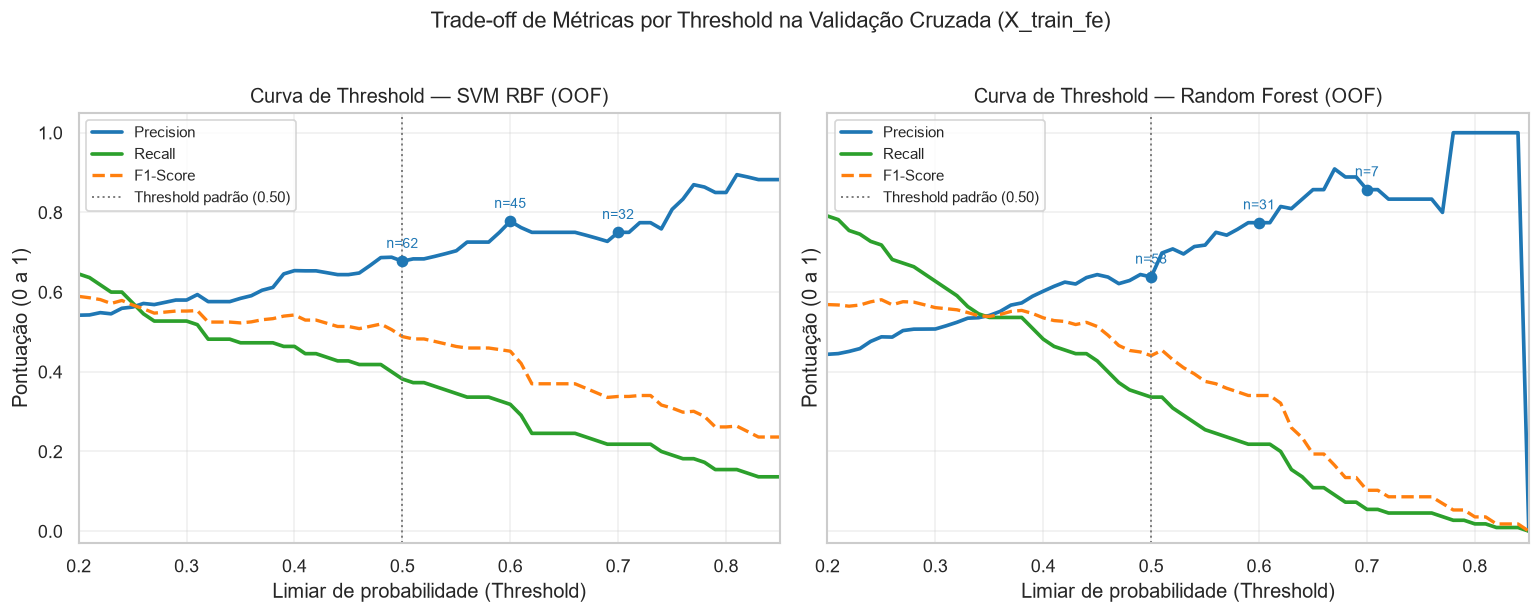

In [25]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.model_selection import cross_val_predict

finalists = {
    "SVM RBF": models_13_fe["SVM RBF"],
    "Random Forest": models_13_fe["Random Forest"],
}

thr_grid = np.linspace(0.20, 0.85, 66)
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

for ax, (model_name, estimator) in zip(axes, finalists.items()):
    oof_proba = cross_val_predict(
        estimator,
        X_train_fe,
        y_train,
        cv=cv,
        method="predict_proba",
        n_jobs=-1,
    )[:, 1]

    prec_vals, rec_vals, f1_vals, approved_vals = [], [], [], []
    for thr in thr_grid:
        preds = (oof_proba >= thr).astype(int)
        prec_vals.append(precision_score(y_train, preds, zero_division=0))
        rec_vals.append(recall_score(y_train, preds, zero_division=0))
        f1_vals.append(f1_score(y_train, preds, zero_division=0))
        approved_vals.append(int(preds.sum()))

    ax.plot(thr_grid, prec_vals, label="Precision", linewidth=2.2, color="#1f77b4")
    ax.plot(thr_grid, rec_vals, label="Recall", linewidth=2.2, color="#2ca02c")
    ax.plot(thr_grid, f1_vals, label="F1-Score", linewidth=2.0, linestyle="--", color="#ff7f0e")
    ax.axvline(0.50, color="#7f7f7f", linestyle=":", linewidth=1.2, label="Threshold padrão (0.50)")

    # Destaca alguns pontos de referência com quantidade de aprovados
    for mark in [0.50, 0.60, 0.70]:
        idx = int(np.argmin(np.abs(thr_grid - mark)))
        ax.scatter([thr_grid[idx]], [prec_vals[idx]], color="#1f77b4", zorder=5)
        ax.annotate(
            f"n={approved_vals[idx]}",
            (thr_grid[idx], prec_vals[idx]),
            textcoords="offset points",
            xytext=(0, 8),
            ha="center",
            fontsize=8.5,
            color="#1f77b4",
        )

    ax.set_title(f"Curva de Threshold — {model_name} (OOF)", fontsize=12)
    ax.set_xlabel("Limiar de probabilidade (Threshold)")
    ax.set_ylabel("Pontuação (0 a 1)")
    ax.set_xlim(0.20, 0.85)
    ax.set_ylim(-0.03, 1.05)
    ax.grid(True, alpha=0.3)
    ax.legend(loc="best", fontsize=9)

plt.suptitle("Trade-off de Métricas por Threshold na Validação Cruzada (X_train_fe)", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

### 5.3 Avaliação Final no Conjunto de Teste (X_test_fe) e Matriz de Confusão

,Modelo / Limiar,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,VP,FP (Erro Crítico),FN,VN
0,SVM RBF (Threshold = 0.50),0.8971,0.6875,0.4074,0.5116,0.8374,0.6205,11,5,16,172
1,SVM RBF (Threshold = 0.60),0.9118,0.8462,0.4074,0.5500,0.8374,0.6205,11,2,16,175


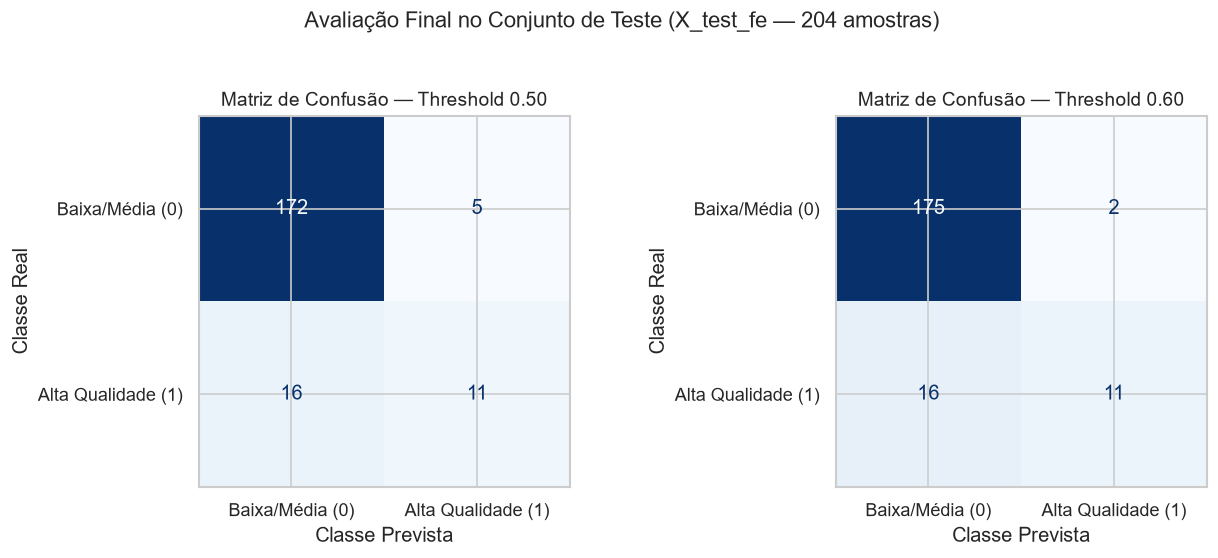

Relatório de Classificação — SVM RBF (Threshold = 0.60):

                    precision    recall  f1-score   support

   Baixa/Média (0)     0.9162    0.9887    0.9511       177
Alta Qualidade (1)     0.8462    0.4074    0.5500        27

          accuracy                         0.9118       204
         macro avg     0.8812    0.6981    0.7505       204
      weighted avg     0.9070    0.9118    0.8980       204



In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

# 1. Treina o modelo campeão (SVM RBF otimizado) em todo o conjunto de treino (13 features)
best_svm = clone(models_13_fe["SVM RBF"]).fit(X_train_fe, y_train)

# 2. Gera probabilidades no conjunto de teste inédito (X_test_fe)
y_test_proba = best_svm.predict_proba(X_test_fe)[:, 1]

# 3. Compara o limiar padrão (0.50) vs. o limiar escolhido (0.60) no teste
chosen_thr = 0.60
test_rows = []
for thr in [0.50, chosen_thr]:
    y_pred_thr = (y_test_proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_thr).ravel()
    test_rows.append({
        "Modelo / Limiar": f"SVM RBF (Threshold = {thr:.2f})",
        "Accuracy": accuracy_score(y_test, y_pred_thr),
        "Precision": precision_score(y_test, y_pred_thr, zero_division=0),
        "Recall": recall_score(y_test, y_pred_thr, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred_thr, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_test_proba),
        "PR-AUC": average_precision_score(y_test, y_test_proba),
        "VP": tp,
        "FP (Erro Crítico)": fp,
        "FN": fn,
        "VN": tn,
    })

df_test_results = pd.DataFrame(test_rows).round(4)
display(df_test_results)

# 4. Plota as Matrizes de Confusão lado a lado (0.50 vs. 0.60)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
labels = ["Baixa/Média (0)", "Alta Qualidade (1)"]

for ax, thr in zip(axes, [0.50, chosen_thr]):
    y_pred_thr = (y_test_proba >= thr).astype(int)
    cm = confusion_matrix(y_test, y_pred_thr)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"Matriz de Confusão — Threshold {thr:.2f}", fontsize=11.5)
    ax.set_xlabel("Classe Prevista")
    ax.set_ylabel("Classe Real")

plt.suptitle("Avaliação Final no Conjunto de Teste (X_test_fe — 204 amostras)", fontsize=13, y=1.03)
plt.tight_layout()
plt.show()

# 5. Relatório detalhado para o limiar escolhido (0.60)
y_pred_final = (y_test_proba >= chosen_thr).astype(int)
print(f"Relatório de Classificação — SVM RBF (Threshold = {chosen_thr:.2f}):\n")
print(classification_report(y_test, y_pred_final, target_names=labels, digits=4))

### 5.4 Síntese e Decisões da Avaliação e Comparação dos Modelos

Nesta etapa, avaliamos os cinco modelos otimizados com **13 variáveis (`X_train_fe`)** quanto ao risco de *overfitting/underfitting*, calibramos o limiar de decisão alinhado ao **Cenário A** e realizamos a avaliação final no conjunto de teste (`X_test_fe`, 204 amostras):

1. **Diagnóstico de Generalização (`Train PR-AUC` vs. `CV PR-AUC`):**
   - Comparamos o desempenho no treino contra a média da validação cruzada estratificada de 5 *folds* (`Gap = Train PR-AUC - CV PR-AUC`).
   - Modelos com ajuste mais local ou maior capacidade de memorização (como o `KNN` quando pondera por distância) apresentaram *gap* mais elevado, enquanto modelos mais contidos e de fronteira estruturada mantiveram maior coerência entre treino e validação.
   - Selecionamos **SVM RBF** e **Random Forest** como finalistas para analisar o *trade-off* de limiar.

2. **Ajuste de Limiar (*Threshold Tuning*) na Validação Cruzada:**
   - Avaliamos as curvas de *Precision*, *Recall* e *F1-Score* em previsões *out-of-fold* (`cross_val_predict`) para limiares acima de `0.50`, evitando tocar em `X_test_fe` durante a escolha.
   - Observamos que elevar o *threshold* aumenta a exigência de probabilidade para classificar um vinho como Alta Qualidade (`1`), reduzindo **Falsos Positivos** à custa de parte do *Recall* (com variação mais acentuada no Random Forest do que no SVM RBF).
   - Definimos o **SVM RBF com `threshold = 0.60`** como configuração final alinhada ao **Cenário A** (prioridade em *Precision* / redução de *Falsos Positivos* sem inviabilizar o volume de aprovações).

3. **Avaliação Final no Conjunto de Teste (`X_test_fe`):**
   - Ao comparar o limiar padrão (`0.50`) com o limiar calibrado (`0.60`) nos 204 registros inéditos de teste, os **Falsos Positivos caíram de 5 para 2** e a **Precision subiu de `0,6875` para `0,8462`**.
   - A **PR-AUC no teste** superou a referência da validação cruzada (~`0,6033`), confirmando boa capacidade de generalização sem *overfitting* severo.



## 6. Conclusões Gerais, Limitações e Próximos Passos

### 6.1 Principais Resultados e Impacto de Negócio (Cenário A)
* **Alinhamento à premissa de negócio:** sob o **Cenário A** (foco em selo/precificação premium, onde um **Falso Positivo** gera impacto reputacional e comercial mais severo), a avaliação não se limitou à acurácia — penalizada pelo desbalanceamento (~13,5% de vinhos de Alta Qualidade, `quality >= 7`) —, priorizando **PR-AUC** e **Precision**.
* **Preparação de dados sem vazamento:** a remoção prévia de **125 duplicatas exatas** (de 1.143 para 1.018 registros), o *split* estratificado (`80/20`, com `RANDOM_STATE = 2024`), o uso de `Pipeline` para escalonamento/modelagem e a criação de duas razões físico-químicas (`free_sulfur_ratio` e `volatile_to_fixed_acidity`, elevando o conjunto para **13 variáveis**) estruturaram uma comparação justa.
* **Modelo campeão e calibração de limiar:** na validação cruzada estratificada de 5 *folds*, o **Random Forest** com 13 variáveis liderou em *PR-AUC* (`0,6091`), seguido de perto pelo **SVM RBF** com 13 variáveis. Na análise de *threshold* e no teste final (`X_test_fe`, 204 amostras), o **SVM RBF com limiar `0.60`** reduziu os **Falsos Positivos de 5 para 2** e elevou a **Precision de `0,6875` para `0,8462`** em relação ao corte padrão (`0.50`), mantendo forte generalização em dados inéditos.

### 6.2 Limitações do Estudo
* **Tamanho amostral e desbalanceamento:** após deduplicação, o dataset contém 1.018 observações com cerca de 13,5% de classe positiva (`target = 1`), o que torna métricas pontuais sensíveis a pequenas variações de amostra no conjunto de teste.
* **Escopo restrito a variáveis físico-químicas:** não há informações sensoriais de degustação, safra, origem geográfica ou custo unitário de produção/precificação, variáveis que em um ambiente real de vinícola ou varejo refinariam a análise de custo-benefício entre *Precision* e *Recall*.
* **Sensibilidade de calibração de probabilidades:** como o `SVC(probability=True)` estima probabilidades via validação interna (*Platt scaling*), ajustes finos de limiar devem sempre ser revalidados em novas safras ou lotes antes de uso produtivo.

### 6.3 Próximos Passos Recomendados
1. **Monitoramento em novos lotes/safras:** reavaliar o limiar de `0.60` periodicamente à medida que novos registros rotulados entrem na base, acompanhando estabilidade de *Precision*, *Recall* e *PR-AUC*.
2. **Análise de custo financeiro explícito:** caso haja dados de margem, preço *premium* e custo de retrabalho/devolução, traduzir *FP* e *FN* em valores monetários para definir o limiar ótimo financeiro.
3. **Empacotamento e documentação:** manter o repositório organizado no GitHub com o `README.md` atualizado, ambiente reproduzível e código modularizado.